# Weather Trend Forecasting
## Notebook 04: More models, an ensemble, and feature importance

Same task as notebook 03: tomorrow's temperature (C) in six cities, one model per city, using only past data.
Same feature table (`data/processed/city_features.csv`), same train / validation / test windows, same test days.

Models:
1. **Ridge** (from notebook 03), linear
2. **Random Forest**, many decision trees averaged, can learn non-linear patterns
3. **Gradient Boosting**, trees added one after another, each one correcting the previous ones
4. **SARIMAX**, a classic time series model: ARMA errors plus the seasonal Fourier terms and snapshot hour as
   inputs. A seasonal ARIMA with a 365-day season is not possible with only about two years of data, so the
   Fourier terms describe the yearly cycle instead.
5. **Ensembles**: a simple average of the four models, and a weighted average whose weights are chosen on the
   validation window only

Compared against the same two baselines: naive (yesterday) and seasonal naive (same day last year).

How the windows are used:
- Every model is fit on **train** and scored on **validation**. Ridge's penalty, the SARIMAX order and the ensemble
  weights are chosen here.
- Every model is then refit on **train + validation** with those choices and predicts the **test** window one day
  at a time, using the real value of the previous day. The test window is used once, for the final table.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FIG = Path('../reports/figures')
PROC = Path('../data/processed')
METRICS = Path('../reports/metrics')
METRICS.mkdir(parents=True, exist_ok=True)

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold',
})
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GREY = '#8a8984'
CITIES = ['Moscow', 'London', 'New Delhi', 'Singapore', 'Canberra', 'Buenos Aires']

def save(fig, name):
    fig.savefig(FIG / name)
    print('saved', FIG / name)

import warnings
from scipy.optimize import minimize
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_regression
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings('ignore', module='statsmodels')

In [2]:
feats = pd.read_csv(PROC / 'city_features.csv', parse_dates=['date']).set_index('date')
FEATURES = ['lag1', 'lag2', 'lag3', 'lag7', 'roll7', 'roll30', 'sin1', 'cos1', 'sin2', 'cos2',
            'humidity_lag1', 'cloud_lag1', 'wind_lag1', 'precip_lag1', 'pressure_lag1', 'pressure_change', 'hour_lag1']
print(feats.shape)
print(feats.groupby(['city', 'split']).size().unstack()[['train', 'val', 'test']].loc[CITIES])
print('test window:', feats[feats['split'] == 'test'].index.min().date(), 'to', feats[feats['split'] == 'test'].index.max().date())

(5070, 22)
split         train  val  test
city                          
Moscow          667   90    89
London          665   90    89
New Delhi       665   90    89
Singapore       667   90    89
Canberra        667   90    89
Buenos Aires    665   90    89
test window: 2026-07-16 to 2026-10-13


In [3]:
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = y - p
    denom = np.abs(y) + np.abs(p)
    return {
        'MAE': np.mean(np.abs(e)),
        'RMSE': np.sqrt(np.mean(e ** 2)),
        'sMAPE': 100 * np.mean(np.where(denom > 0, 2 * np.abs(e) / denom, 0)),
        'R2': r2_score(y, p),
    }

## 1. The machine learning models

All three predict the **change from yesterday** and add yesterday's value back, as in notebook 03. For the tree
models this matters: a tree cannot predict a value outside what it saw in training, but changes from one day to the
next are similar in every season, so predicting the change avoids that problem.

Settings are fixed and modest (no large search):
- Ridge: `alpha` chosen on validation from 0.1, 1, 10, 100
- Random Forest: 300 trees, at least 5 rows per leaf, half of the features tried at each split
- Gradient Boosting: 300 trees of depth 3, learning rate 0.03, each tree sees 80% of the rows

In [4]:
ALPHAS = [0.1, 1, 10, 100]

def make_model(name, alpha=None):
    if name == 'ridge':
        return make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    if name == 'random forest':
        return RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=0)
    if name == 'gradient boosting':
        return GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8, random_state=0)

def fit_predict(name, fit_df, pred_df, alpha=None):
    model = make_model(name, alpha)
    model.fit(fit_df[FEATURES], fit_df['y'] - fit_df['lag1'])
    return model, model.predict(pred_df[FEATURES]) + pred_df['lag1'].values

In [5]:
ML = ['ridge', 'random forest', 'gradient boosting']
val_pred, test_pred, alpha_choice, fitted = {}, {}, {}, {}

for city in CITIES:
    c = feats[feats['city'] == city]
    tr, va, te = c[c['split'] == 'train'], c[c['split'] == 'val'], c[c['split'] == 'test']
    trva = c[c['split'] != 'test']

    scores = {a: metrics(va['y'], fit_predict('ridge', tr, va, a)[1])['MAE'] for a in ALPHAS}
    alpha_choice[city] = min(scores, key=scores.get)

    vp = pd.DataFrame({'y': va['y'], 'naive (yesterday)': va['lag1'], 'seasonal naive (last year)': va['lag365']})
    tp = pd.DataFrame({'y': te['y'], 'naive (yesterday)': te['lag1'], 'seasonal naive (last year)': te['lag365']})
    for name in ML:
        vp[name] = fit_predict(name, tr, va, alpha_choice[city])[1]
        fitted[(city, name)], tp[name] = fit_predict(name, trva, te, alpha_choice[city])
    val_pred[city], test_pred[city] = vp, tp

print('ridge alpha chosen on validation:', alpha_choice)

ridge alpha chosen on validation: {'Moscow': 100, 'London': 100, 'New Delhi': 0.1, 'Singapore': 100, 'Canberra': 10, 'Buenos Aires': 10}


## 2. SARIMAX

The model is fit on the full daily calendar. Days without a snapshot are left empty and the model handles them
(Kalman filter). Inputs: the four Fourier terms and yesterday's snapshot hour, the same calendar and hour
information the other models get.

The order (how many past values and past errors are used) is chosen by AIC on the training window from three
small options. Predictions are one day ahead: the model parameters stay fixed, but each forecast uses the real
temperature of the previous day.

In [6]:
EXOG = ['sin1', 'cos1', 'sin2', 'cos2', 'hour_lag1']
ORDERS = [(1, 0, 0), (1, 0, 1), (2, 0, 1)]

def calendar_frame(city):
    c = feats[feats['city'] == city]
    cal = pd.date_range(c.index.min(), c.index.max(), freq='D')
    f = c.reindex(cal)
    doy = cal.day_of_year / 365.25
    for k in [1, 2]:
        f[f'sin{k}'] = np.sin(2 * np.pi * k * doy)
        f[f'cos{k}'] = np.cos(2 * np.pi * k * doy)
    f['hour_lag1'] = f['hour_lag1'].ffill()
    return f

def sarimax_one_step(f, fit_end, pred_start, pred_end, order):
    fit = f.loc[:fit_end]
    res = SARIMAX(fit['y'], exog=fit[EXOG], order=order, trend='c').fit(disp=False, maxiter=200)
    ext = res.append(f.loc[pred_start:pred_end, 'y'], exog=f.loc[pred_start:pred_end, EXOG], refit=False)
    return res, ext.predict(start=pred_start, end=pred_end)

VAL_START, TEST_START = pd.Timestamp('2026-04-17'), pd.Timestamp('2026-07-16')
order_choice = {}
for city in CITIES:
    f = calendar_frame(city)
    train_end = VAL_START - pd.Timedelta(days=1)
    aic = {o: SARIMAX(f.loc[:train_end, 'y'], exog=f.loc[:train_end, EXOG], order=o, trend='c')
              .fit(disp=False, maxiter=200).aic for o in ORDERS}
    order_choice[city] = min(aic, key=aic.get)

    _, pv = sarimax_one_step(f, train_end, VAL_START, TEST_START - pd.Timedelta(days=1), order_choice[city])
    _, pt = sarimax_one_step(f, TEST_START - pd.Timedelta(days=1), TEST_START, f.index.max(), order_choice[city])
    val_pred[city]['sarimax'] = pv.reindex(val_pred[city].index).values
    test_pred[city]['sarimax'] = pt.reindex(test_pred[city].index).values

print('SARIMAX order chosen by AIC on train:', order_choice)

SARIMAX order chosen by AIC on train: {'Moscow': (1, 0, 0), 'London': (1, 0, 1), 'New Delhi': (2, 0, 1), 'Singapore': (1, 0, 1), 'Canberra': (2, 0, 1), 'Buenos Aires': (2, 0, 1)}


## 3. Ensembles

Two ways to combine the four models:
- **Average:** equal weights, nothing is fitted.
- **Weighted:** for each city, weights (zero or positive, adding up to 1) that give the lowest squared error on
  the **validation** window. The same weights are then applied to the test forecasts. The test window plays no
  part in choosing them.

In [7]:
MODELS = ['ridge', 'random forest', 'gradient boosting', 'sarimax']

def fit_weights(P, y):
    k = P.shape[1]
    loss = lambda w: np.mean((P @ w - y) ** 2)
    res = minimize(loss, np.full(k, 1 / k), method='SLSQP', bounds=[(0, 1)] * k,
                   constraints={'type': 'eq', 'fun': lambda w: w.sum() - 1})
    return res.x

weights = {}
for city in CITIES:
    vp, tp = val_pred[city], test_pred[city]
    w = fit_weights(vp[MODELS].values, vp['y'].values)
    weights[city] = w
    for p in (vp, tp):
        p['ensemble (average)'] = p[MODELS].mean(axis=1)
        p['ensemble (weighted)'] = p[MODELS].values @ w

weights = pd.DataFrame(weights, index=MODELS).T.loc[CITIES]
weights.to_csv(METRICS / '04_ensemble_weights.csv')
weights.round(2)

,ridge,random forest,gradient boosting,sarimax
Moscow,0.18,0.39,0.29,0.14
London,0.82,0.18,0.00,0.00
New Delhi,0.67,0.33,0.00,0.00
Singapore,0.07,0.25,0.61,0.07
Canberra,0.88,0.00,0.04,0.08
Buenos Aires,0.43,0.00,0.30,0.26


saved ../reports/figures/04_ensemble_weights.png


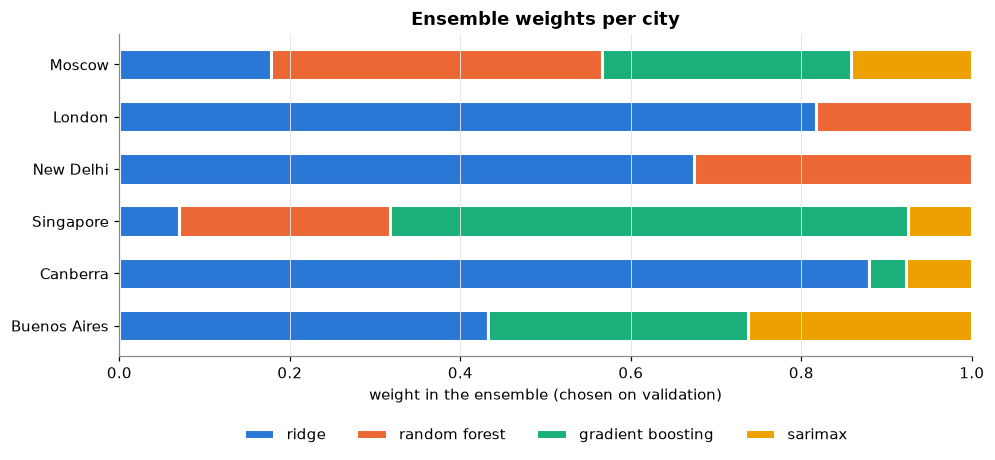

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
left = np.zeros(len(CITIES))
for color, m in zip(PALETTE, MODELS):
    ax.barh(CITIES, weights[m], left=left, color=color, height=0.6, label=m, edgecolor='white', linewidth=2)
    left += weights[m].values
ax.set_xlabel('weight in the ensemble (chosen on validation)')
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.set_title('Ensemble weights per city')
ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.18))
ax.grid(axis='y', visible=False)
save(fig, '04_ensemble_weights.png')
plt.show()

## 4. Validation results (used for choices, not for the final verdict)

In [9]:
ALL = ['naive (yesterday)', 'seasonal naive (last year)'] + MODELS + ['ensemble (average)', 'ensemble (weighted)']

def score(preds, split):
    rows = []
    for city in CITIES:
        p = preds[city]
        for m in ALL:
            rows.append({'split': split, 'city': city, 'model': m, **metrics(p['y'], p[m])})
    return pd.DataFrame(rows)

val_scores = score(val_pred, 'val')
val_scores.to_csv(METRICS / '04_val_metrics.csv', index=False)
val_scores.pivot(index='city', columns='model', values='MAE').loc[CITIES, ALL].round(2)

model,naive (yesterday),seasonal naive (last year),ridge,random forest,gradient boosting,sarimax,ensemble (average),ensemble (weighted)
city,,,,,,,,
Moscow,2.44,7.06,2.31,2.33,2.33,2.43,2.27,2.27
London,1.73,4.21,1.59,1.67,1.76,1.78,1.62,1.58
New Delhi,2.28,3.30,2.07,2.10,2.52,2.09,2.12,2.05
Singapore,2.10,1.97,1.58,1.59,1.54,1.56,1.54,1.53
Canberra,1.86,5.98,1.68,1.81,1.80,2.79,1.77,1.67
Buenos Aires,2.52,3.71,2.04,2.11,2.07,2.17,1.95,1.96


## 5. Test results

Every model below is scored on exactly the same days (89 per city). This is the only time the test window is used.

In [10]:
test_scores = score(test_pred, 'test')
test_scores.to_csv(METRICS / '04_test_metrics.csv', index=False)
mae = test_scores.pivot(index='city', columns='model', values='MAE').loc[CITIES, ALL]
mae.round(2)

model,naive (yesterday),seasonal naive (last year),ridge,random forest,gradient boosting,sarimax,ensemble (average),ensemble (weighted)
city,,,,,,,,
Moscow,1.96,3.87,1.77,1.83,1.77,1.88,1.77,1.77
London,2.11,2.78,1.89,1.91,1.86,1.88,1.85,1.88
New Delhi,1.65,3.61,1.77,1.71,1.83,1.79,1.75,1.74
Singapore,0.81,2.04,1.16,0.83,0.86,1.45,1.04,0.88
Canberra,2.40,3.65,2.13,2.38,2.22,2.39,2.19,2.11
Buenos Aires,2.29,3.79,2.36,2.07,2.08,2.32,2.13,2.17


In [11]:
print('RMSE')
test_scores.pivot(index='city', columns='model', values='RMSE').loc[CITIES, ALL].round(2)

RMSE


model,naive (yesterday),seasonal naive (last year),ridge,random forest,gradient boosting,sarimax,ensemble (average),ensemble (weighted)
city,,,,,,,,
Moscow,2.53,4.99,2.27,2.27,2.25,2.35,2.24,2.24
London,2.60,3.59,2.31,2.35,2.31,2.32,2.28,2.31
New Delhi,2.22,4.48,2.28,2.16,2.30,2.24,2.21,2.22
Singapore,1.49,2.40,1.51,1.33,1.37,1.73,1.44,1.37
Canberra,3.50,4.52,2.97,3.37,3.17,3.17,3.08,2.96
Buenos Aires,2.95,4.56,2.84,2.48,2.46,2.83,2.55,2.62


In [12]:
print('average over the six cities')
avg = test_scores.groupby('model')[['MAE', 'RMSE', 'sMAPE', 'R2']].mean().loc[ALL]
avg['cities better than naive (MAE)'] = [(mae[m] < mae['naive (yesterday)']).sum() for m in ALL]
avg['cities better than seasonal naive (MAE)'] = [(mae[m] < mae['seasonal naive (last year)']).sum() for m in ALL]
avg.round(3)

average over the six cities


,MAE,RMSE,sMAPE,R2,cities better than naive (MAE),cities better than seasonal naive (MAE)
model,,,,,,
naive (yesterday),1.871,2.548,12.792,0.171,0,6
seasonal naive (last year),3.288,4.092,21.210,-1.105,0,0
ridge,1.845,2.365,12.267,0.255,3,6
random forest,1.787,2.330,12.024,0.312,4,6
gradient boosting,1.771,2.312,11.830,0.310,4,6
sarimax,1.951,2.441,12.758,0.168,3,6
ensemble (average),1.787,2.299,11.843,0.304,4,6
ensemble (weighted),1.758,2.285,11.756,0.323,4,6


saved ../reports/figures/04_test_mae_vs_naive.png


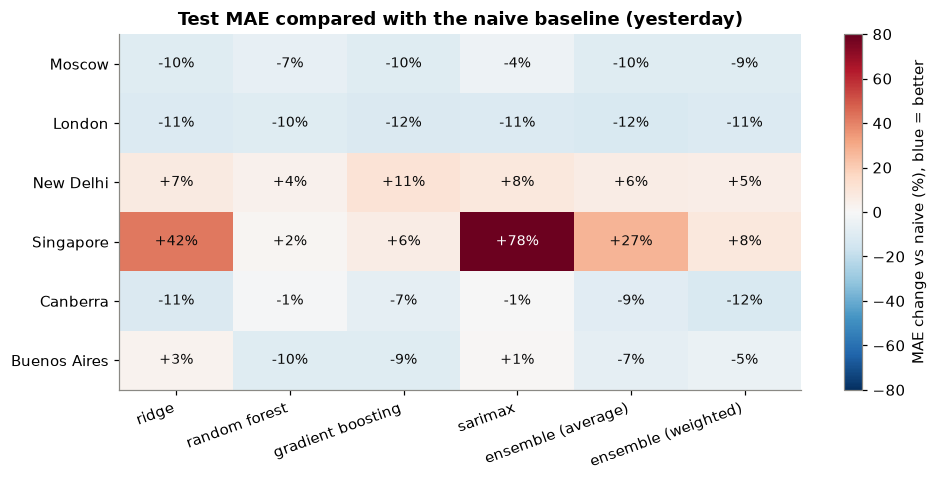

In [13]:
rel = 100 * (mae[MODELS + ['ensemble (average)', 'ensemble (weighted)']].div(mae['naive (yesterday)'], axis=0) - 1)
lim = np.ceil(np.abs(rel.values).max() / 10) * 10

fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(rel.values, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(rel.shape[1]), rel.columns, rotation=20, ha='right')
ax.set_yticks(range(len(CITIES)), CITIES)
ax.grid(False)
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        v = rel.values[i, j]
        ax.text(j, i, f'{v:+.0f}%', ha='center', va='center', fontsize=9, color='white' if abs(v) > lim * 0.6 else '#0b0b0b')
fig.colorbar(im, ax=ax, label='MAE change vs naive (%), blue = better')
ax.set_title('Test MAE compared with the naive baseline (yesterday)')
save(fig, '04_test_mae_vs_naive.png')
plt.show()

saved ../reports/figures/04_test_forecast_ensemble.png


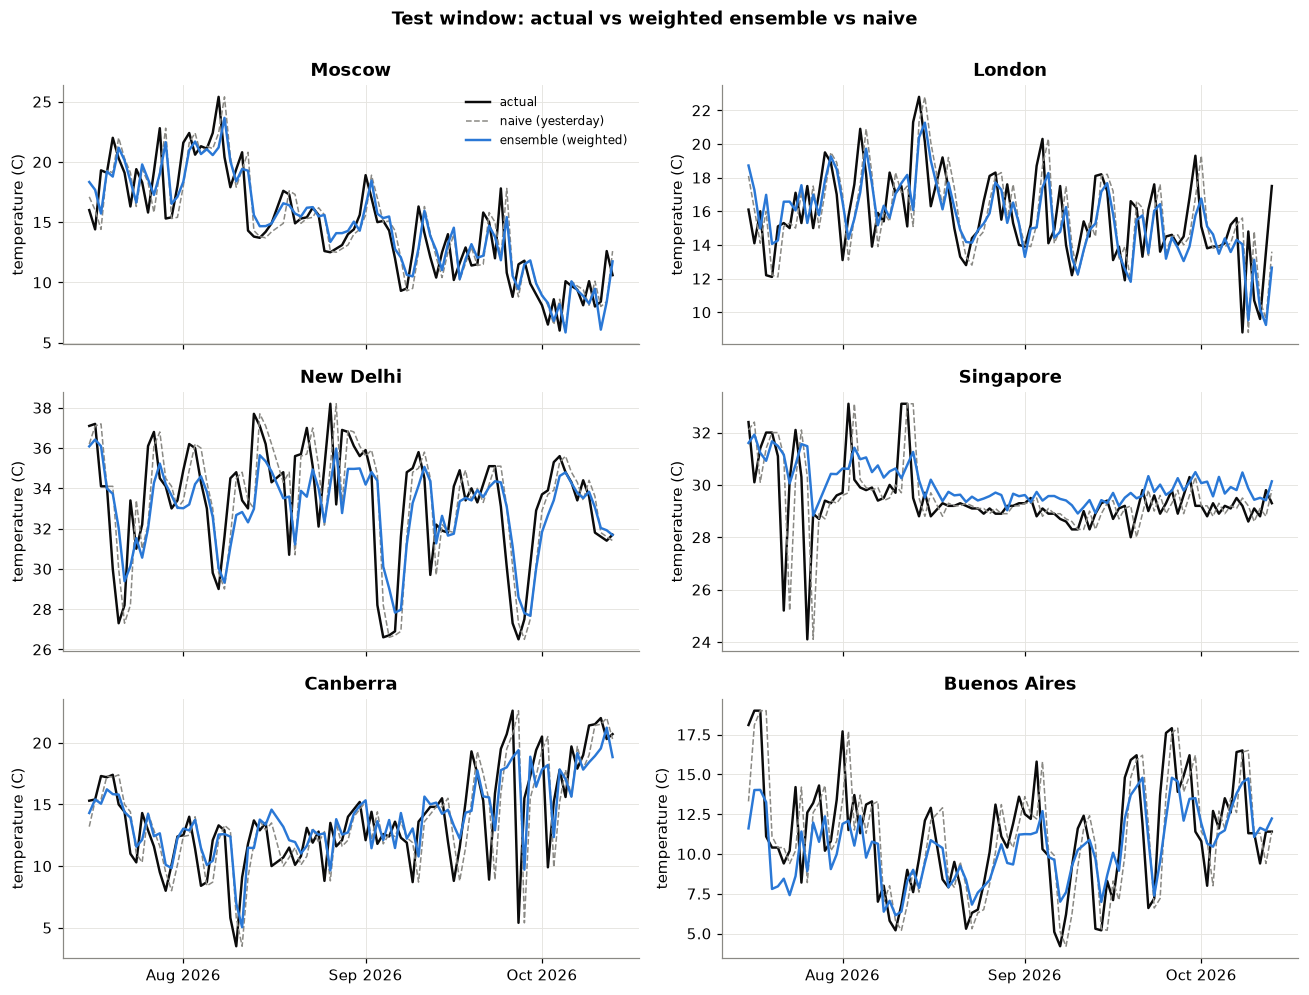

In [14]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, city in zip(axes.flat, CITIES):
    p = test_pred[city]
    ax.plot(p.index, p['y'], color='#0b0b0b', linewidth=1.6, label='actual')
    ax.plot(p.index, p['naive (yesterday)'], color=GREY, linewidth=1, linestyle='--', label='naive (yesterday)')
    ax.plot(p.index, p['ensemble (weighted)'], color=PALETTE[0], linewidth=1.6, label='ensemble (weighted)')
    ax.set_title(city)
    ax.set_ylabel('temperature (C)')
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle('Test window: actual vs weighted ensemble vs naive', y=1.0, fontweight='bold')
fig.tight_layout()
save(fig, '04_test_forecast_ensemble.png')
plt.show()

### Is any result too good?

A one-day-ahead temperature forecast much more than about 30% better than "same as yesterday" would point to leakage.

In [15]:
gain = -rel
print('largest improvement over naive on test:', round(gain.values.max(), 1), '%')
print('flag for review:', bool((gain > 30).any().any()))

largest improvement over naive on test: 12.4 %
flag for review: False


## 6. Feature importance, three ways

Each method answers a slightly different question, so they are compared side by side:
1. **Random Forest impurity importance:** how much each feature helped the trees split the training data. Fast, but
   it favours features with many distinct values.
2. **Permutation importance (Gradient Boosting, validation window):** how much the validation error grows when one
   feature's values are shuffled. This measures what the model really uses on unseen data. The models here were fit
   on train only, so the validation window is unseen.
3. **Mutual information:** a model-free measure of how much each feature tells about the next day's change, on the
   training window.

Each is computed per city, scaled to sum to 1, then averaged over the six cities.

In [16]:
imp_rows = []
for city in CITIES:
    c = feats[feats['city'] == city]
    tr, va = c[c['split'] == 'train'], c[c['split'] == 'val']
    target_tr, target_va = tr['y'] - tr['lag1'], va['y'] - va['lag1']

    rf = make_model('random forest').fit(tr[FEATURES], target_tr)
    gb = make_model('gradient boosting').fit(tr[FEATURES], target_tr)
    perm = permutation_importance(gb, va[FEATURES], target_va, n_repeats=5, random_state=0,
                                  scoring='neg_mean_absolute_error', n_jobs=-1).importances_mean
    mi = mutual_info_regression(tr[FEATURES], target_tr, random_state=0)

    for name, v in [('random forest impurity', rf.feature_importances_),
                    ('permutation (gradient boosting)', np.clip(perm, 0, None)),
                    ('mutual information', mi)]:
        v = v / v.sum() if v.sum() > 0 else v
        imp_rows += [{'city': city, 'method': name, 'feature': f, 'importance': x} for f, x in zip(FEATURES, v)]

imp = pd.DataFrame(imp_rows).groupby(['method', 'feature'])['importance'].mean().unstack(0)
imp = imp.sort_values('permutation (gradient boosting)', ascending=False)
imp.to_csv(METRICS / '04_feature_importance.csv')
imp.round(3)

method,mutual information,permutation (gradient boosting),random forest impurity
feature,,,
lag1,0.203,0.438,0.169
pressure_lag1,0.137,0.093,0.103
humidity_lag1,0.151,0.088,0.094
cos1,0.026,0.070,0.057
pressure_change,0.057,0.062,0.064
roll30,0.031,0.053,0.050
cloud_lag1,0.058,0.049,0.037
roll7,0.042,0.028,0.046
precip_lag1,0.075,0.028,0.022


saved ../reports/figures/04_feature_importance.png


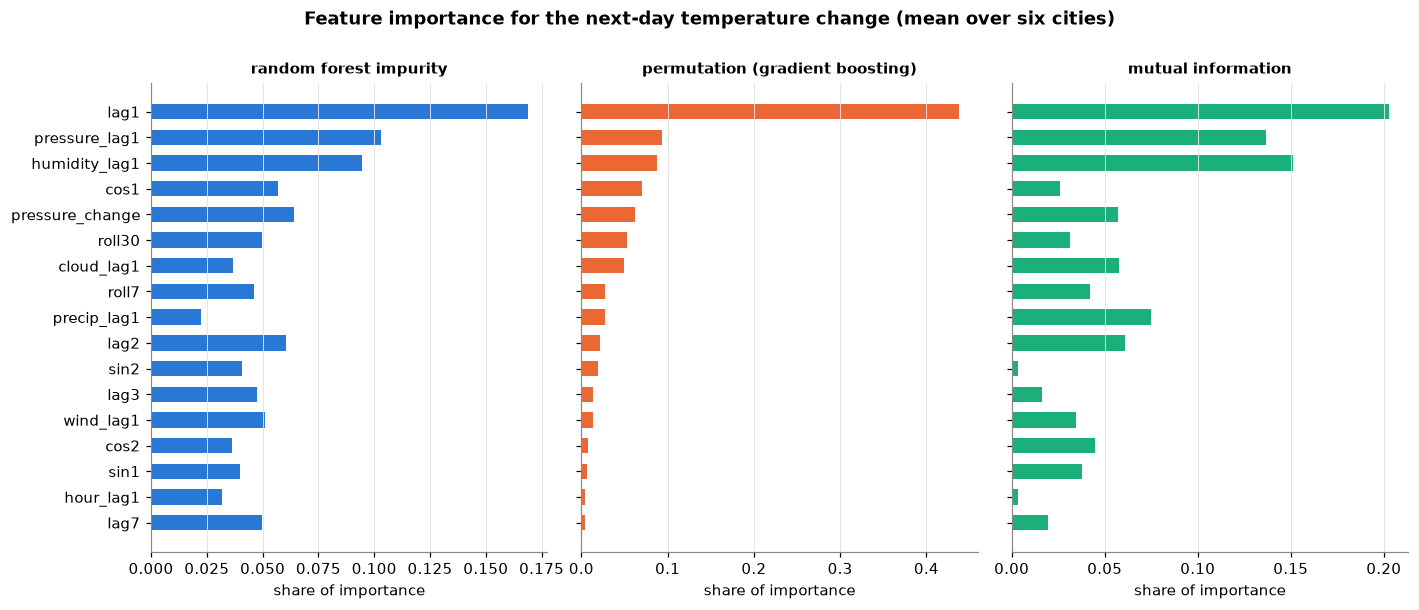

In [17]:
methods = ['random forest impurity', 'permutation (gradient boosting)', 'mutual information']
order = imp.index[::-1]
fig, axes = plt.subplots(1, 3, figsize=(13, 5.5), sharey=True)
for ax, m, color in zip(axes, methods, PALETTE):
    ax.barh(order, imp.loc[order, m], color=color, height=0.6)
    ax.set_title(m, fontsize=10)
    ax.set_xlabel('share of importance')
    ax.grid(axis='y', visible=False)
fig.suptitle('Feature importance for the next-day temperature change (mean over six cities)', y=1.0, fontweight='bold')
fig.tight_layout()
save(fig, '04_feature_importance.png')
plt.show()

In [18]:
print('top 5 features per method:')
for m in methods:
    print(f'{m:35s}', list(imp[m].sort_values(ascending=False).index[:5]))
print()
print('rank correlation between methods (Spearman):')
print(imp.corr(method='spearman').round(2))

top 5 features per method:
random forest impurity              ['lag1', 'pressure_lag1', 'humidity_lag1', 'pressure_change', 'lag2']
permutation (gradient boosting)     ['lag1', 'pressure_lag1', 'humidity_lag1', 'cos1', 'pressure_change']
mutual information                  ['lag1', 'humidity_lag1', 'pressure_lag1', 'precip_lag1', 'lag2']

rank correlation between methods (Spearman):
method                           mutual information  permutation (gradient boosting)  random forest impurity
method                                                                                                      
mutual information                             1.00                             0.65                    0.44
permutation (gradient boosting)                0.65                             1.00                    0.67
random forest impurity                         0.44                             0.67                    1.00


## Summary

All test numbers are on the same 89 days per city (16 Jul to 13 Oct 2026, without 17 August).

**Overall**
- The **weighted ensemble** has the lowest average test MAE: 1.76 C, against 1.87 C for naive (about 6% better)
  and 3.29 C for seasonal naive. Average RMSE: 2.29 vs 2.55 C.
- Gradient Boosting (1.77) and Random Forest (1.79) come next. Ridge (1.85) is just ahead of naive.
  **SARIMAX is worse than naive on average (1.95 C)**, mainly because of Singapore.
- Every model beats the seasonal naive baseline in every city.
- The weighted ensemble was the best method on validation in four cities and the average ensemble in the other two,
  so choosing the weighted ensemble before looking at the test window was a reasonable decision.

**By city (weighted ensemble vs naive, test MAE)**
- Better than naive in four cities: Moscow (1.77 vs 1.96 C), London (1.88 vs 2.11), Canberra (2.11 vs 2.40)
  and Buenos Aires (2.17 vs 2.29).
- **Not better in New Delhi (1.74 vs 1.65) or Singapore (0.88 vs 0.81).** No model beats naive on MAE in these two
  cities. In Singapore the readings become almost constant from September 2026 (see notebook 03), so "same as
  yesterday" is nearly perfect there. On validation the same models were clearly better than naive in Singapore
  (1.53 vs 2.10), so this is a change in the data during the test window, not a model that failed to learn.
- The best single method differs by city (Gradient Boosting in Moscow, the average ensemble in London, Random
  Forest in Buenos Aires). Differences between the models are small, often under 0.1 C.

**Leakage check:** the largest gain over naive is 12.4%, well below the 30% level that would be suspicious.

**Feature importance**
- All three methods put **yesterday's temperature (`lag1`)** first, followed by **yesterday's pressure and humidity**.
  Weather on the day before carries some information about the next day's change, which is plausible because
  pressure and humidity change when a new weather system arrives. The data shows the link, not the cause.
- The seasonal terms and the snapshot hour (`hour_lag1`) matter little for the *change* from one day to the next.
  The hour moves slowly, so its effect is already contained in yesterday's value.
- The methods agree on the top features but not on the rest (rank correlation 0.44 to 0.67). Impurity importance
  spreads credit over many features; permutation importance on validation is the most useful view of what the
  model really relies on.